# Zoo Classifier: Cats vs. Dogs vs. Pandas

**Approach (Option 2):** transfer learning with a pretrained VGG19 backbone, compared against a small from-scratch CNN baseline.
Output layer: 3-way softmax. Loss: `categorical_crossentropy`.

## Step 1: Data Exploration
Before any modeling we need to understand the dataset: how many images there are, whether the classes are balanced,
whether any files are broken, how image dimensions vary, and what the images look like. These findings decide the
input size and preprocessing used in later steps.

### 1.1 Imports and configuration
Only light-weight libraries are needed for exploration. A fixed seed keeps the random image samples reproducible.

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Notebook lives in notebooks/, data in ../data/images/<class>/
DATA_DIR = Path("../data/images")
CLASSES = ["cats", "dogs", "panda"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

assert DATA_DIR.exists(), f"Data folder not found: {DATA_DIR.resolve()}"
print("Data directory:", DATA_DIR.resolve())

Data directory: C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\data\images


### 1.2 Number of images per class
Count the image files in each class folder. A heavily imbalanced dataset would call for class weights or resampling,
and would make plain accuracy a misleading metric.

cats     1000
dogs     1000
panda    1000

Total images: 3000


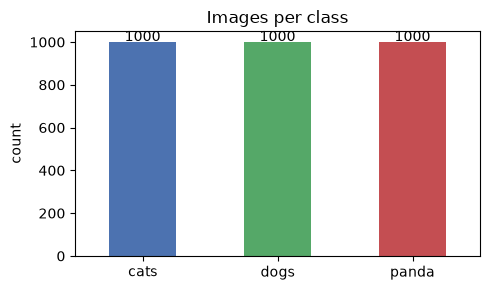

In [2]:
files = {c: sorted(p for p in (DATA_DIR / c).iterdir() if p.suffix.lower() in IMG_EXTS) for c in CLASSES}

counts = pd.Series({c: len(f) for c, f in files.items()}, name="images")
print(counts.to_string())
print(f"\nTotal images: {counts.sum()}")

ax = counts.plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"], rot=0, figsize=(5, 3))
ax.set_title("Images per class")
ax.set_ylabel("count")
for i, v in enumerate(counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()

### 1.3 File integrity and image dimensions
Open every image to record its width, height, and color mode, and flag any file that cannot be decoded.
Corrupt files would crash the training pipeline, and non-RGB modes (grayscale, RGBA, palette) need converting
to 3 channels. `Image.open` is lazy, so this pass only reads headers and is fast.

In [3]:
records, bad_files = [], []
for c, paths in files.items():
    for p in paths:
        try:
            with Image.open(p) as im:
                w, h = im.size
                records.append({"class": c, "file": p.name, "width": w, "height": h, "mode": im.mode, "format": im.format})
        except (UnidentifiedImageError, OSError) as e:
            bad_files.append((str(p), repr(e)))

df = pd.DataFrame(records)
df["aspect"] = df["width"] / df["height"]
df["pixels"] = df["width"] * df["height"]

print(f"Readable images: {len(df)}   Unreadable: {len(bad_files)}")
for path, err in bad_files:
    print("  BAD:", path, err)

print("\nColor modes by class:")
print(pd.crosstab(df["class"], df["mode"]))
print("\nFile formats by class:")
print(pd.crosstab(df["class"], df["format"]))

Readable images: 3000   Unreadable: 0

Color modes by class:
mode   L   RGB
class         
cats   0  1000
dogs   0  1000
panda  7   993

File formats by class:
format  JPEG
class       
cats    1000
dogs    1000
panda   1000


In [4]:
print("Width / height / aspect-ratio summary:")
print(df[["width", "height", "aspect"]].describe().round(2).to_string())

print("\nPer-class median size:")
print(df.groupby("class")[["width", "height"]].median().to_string())

print("\nSmallest 5 images:")
print(df.nsmallest(5, "pixels")[["class", "file", "width", "height"]].to_string(index=False))
print("\nLargest 5 images:")
print(df.nlargest(5, "pixels")[["class", "file", "width", "height"]].to_string(index=False))

Width / height / aspect-ratio summary:
         width   height   aspect
count  3000.00  3000.00  3000.00
mean    431.90   371.62     1.19
std     114.59    96.83     0.27
min      55.00    32.00     0.39
25%     368.00   333.00     0.99
50%     499.00   375.00     1.33
75%     500.00   411.00     1.34
max    1600.00  1200.00     2.81

Per-class median size:
       width  height
class               
cats   475.0   374.0
dogs   419.5   374.0
panda  500.0   375.0

Smallest 5 images:
class           file  width  height
 cats cats_00450.jpg     60      32
 dogs dogs_00631.jpg     59      50
 cats cats_00158.jpg     55      75
 dogs dogs_00874.jpg     86      68
 cats cats_00763.jpg     94      69

Largest 5 images:
class            file  width  height
panda panda_00880.jpg   1600    1200
panda panda_00567.jpg    822    1023
panda panda_00452.jpg   1024     768
panda panda_00664.jpg   1024     768
panda panda_00784.jpg   1024     768


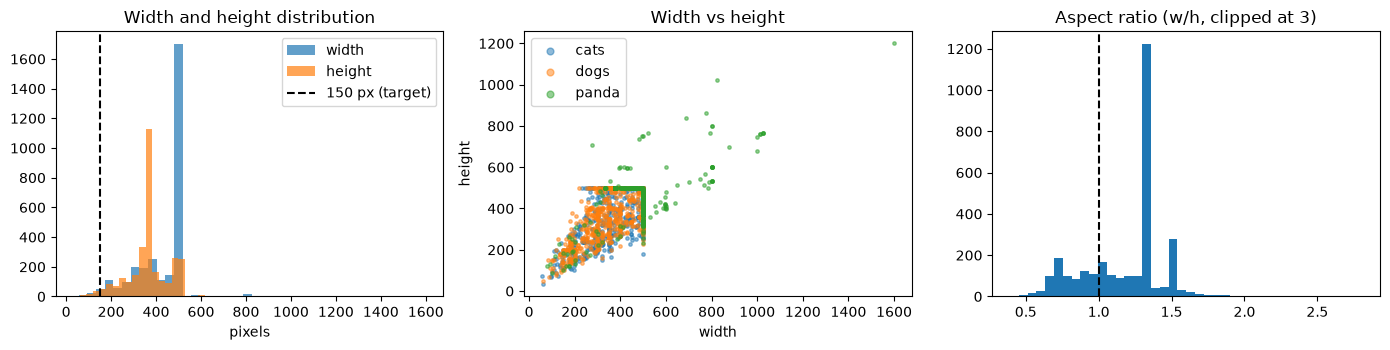

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

axes[0].hist(df["width"], bins=40, alpha=0.7, label="width")
axes[0].hist(df["height"], bins=40, alpha=0.7, label="height")
axes[0].axvline(150, color="k", ls="--", label="150 px (target)")
axes[0].set_title("Width and height distribution")
axes[0].set_xlabel("pixels")
axes[0].legend()

for c in CLASSES:
    sub = df[df["class"] == c]
    axes[1].scatter(sub["width"], sub["height"], s=6, alpha=0.5, label=c)
axes[1].set_title("Width vs height")
axes[1].set_xlabel("width")
axes[1].set_ylabel("height")
axes[1].legend(markerscale=2)

axes[2].hist(df["aspect"].clip(upper=3), bins=40)
axes[2].axvline(1.0, color="k", ls="--")
axes[2].set_title("Aspect ratio (w/h, clipped at 3)")

plt.tight_layout()
plt.show()

### 1.4 Sample images
View a random sample from each class. This is a visual check for label noise, unusual compositions
(multiple animals, drawings, tiny subjects), and how much the images differ in framing and background.

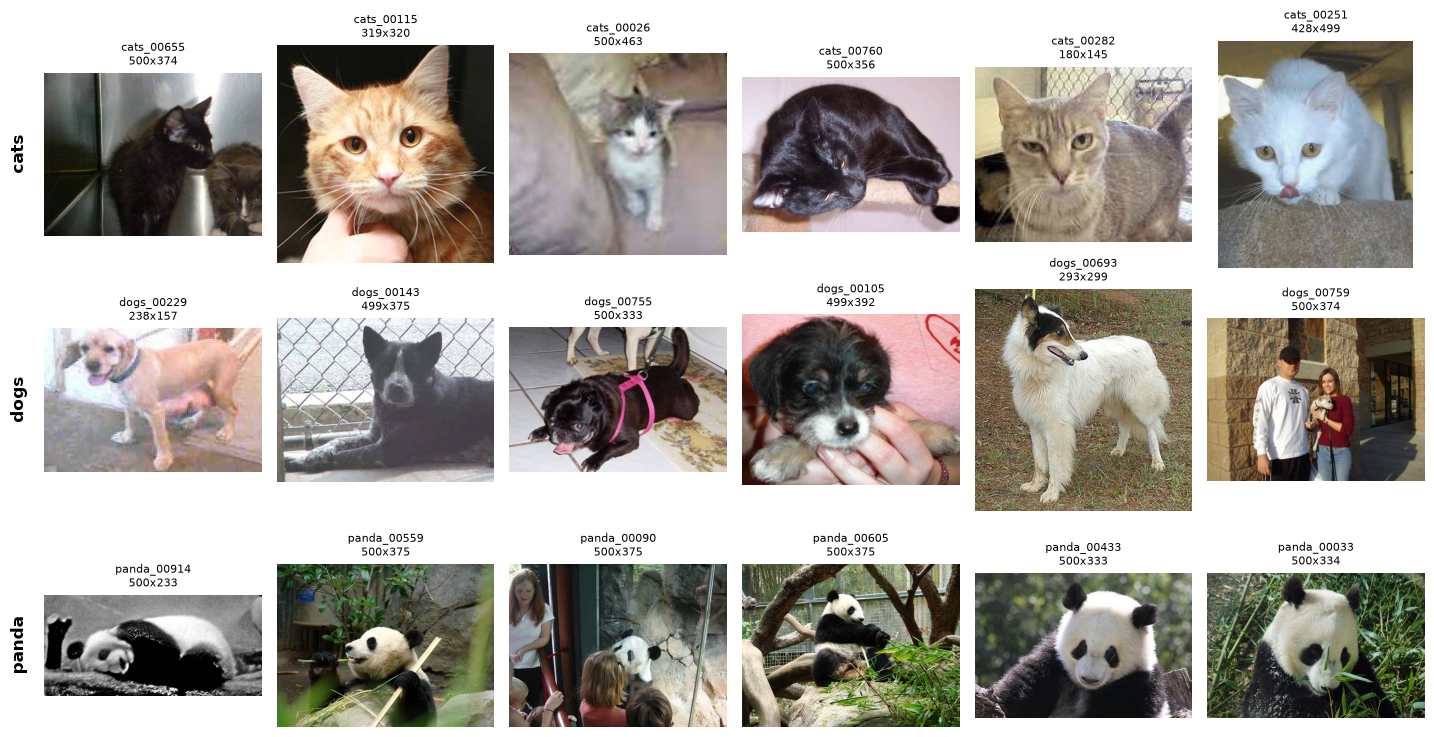

In [6]:
N_SAMPLES = 6
fig, axes = plt.subplots(len(CLASSES), N_SAMPLES, figsize=(2.4 * N_SAMPLES, 2.6 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    for ax, p in zip(axes[r], random.sample(files[c], N_SAMPLES)):
        with Image.open(p) as im:
            ax.imshow(im.convert("RGB"))
            ax.set_title(f"{p.stem}\n{im.size[0]}x{im.size[1]}", fontsize=8)
        ax.axis("off")
    axes[r][0].text(-0.08, 0.5, c, transform=axes[r][0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.5 Preview of the chosen input size
Show the same images resized to the candidate model input of **150 x 150 x 3**, so we can see the effect of squashing
non-square images before committing to this size.

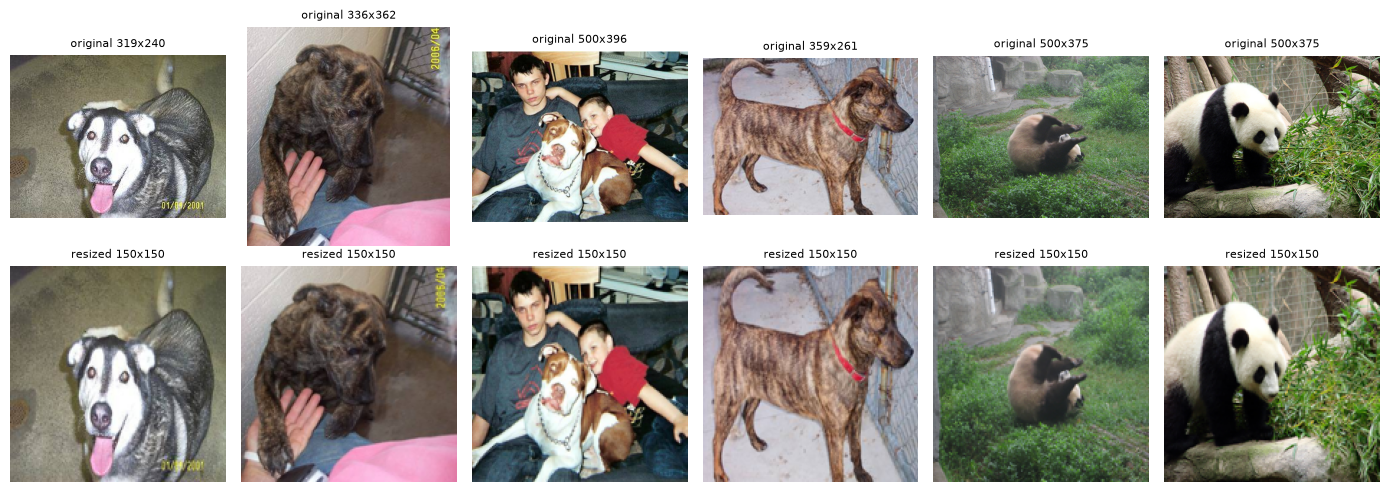

In [7]:
IMG_SIZE = (150, 150)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j, p in enumerate(random.sample(files["dogs"] + files["cats"] + files["panda"], 6)):
    with Image.open(p) as im:
        im = im.convert("RGB")
        axes[0, j].imshow(im)
        axes[0, j].set_title(f"original {im.size[0]}x{im.size[1]}", fontsize=8)
        axes[1, j].imshow(im.resize(IMG_SIZE))
        axes[1, j].set_title("resized 150x150", fontsize=8)
    axes[0, j].axis("off")
    axes[1, j].axis("off")
plt.tight_layout()
plt.show()

### 1.6 Insights and decisions
**Findings**
- **Size and balance:** 3,000 images, exactly 1,000 per class (cats, dogs, panda). The classes are perfectly balanced, so plain accuracy is a fair metric and no class weights or resampling are needed.
- **Integrity:** all 3,000 files are readable JPEGs; none are corrupt.
- **Color modes:** 7 panda images are grayscale (`L`); everything else is RGB. These must be converted to 3 channels (`convert("RGB")`), which Keras `image_dataset_from_directory` does by default (`color_mode="rgb"`).
- **Dimensions vary widely:** widths range from 55 to 1600 px and heights from 32 to 1200 px. The median is about 499 x 375 (aspect about 1.33, i.e. 4:3 landscape). Panda images are the most uniform in size (median 500 x 375), and a few cats and dogs are tiny (for example 60 x 32), so upscaling will blur them.
- **Visual check:** a random sample looks correctly labeled. Backgrounds, poses, lighting, and framing are varied, and some images include people or several animals, which makes this a realistic, non-trivial task. Pandas are distinctive (black and white fur), while cats and dogs are likely to be confused with each other more often.

**Decisions for the next steps**
- **Input size: 150 x 150 x 3**, as suggested in the assignment. It is much smaller than the typical image, which keeps training fast on a laptop and still shows the subject clearly in the resized preview. VGG19 accepts any input of at least 32 x 32, so 150 x 150 works with `include_top=False`.
- **Resizing:** images are mostly 4:3, so a direct resize to square squashes them slightly. This is an acceptable distortion for this task; cropping would risk cutting off the animal. Revisit if the results suggest it matters.
- **Preprocessing:** convert every image to RGB, resize to 150 x 150, and apply `vgg19.preprocess_input` for the transfer model (simple `/255` scaling for the from-scratch baseline).
- **Splitting:** use a stratified train/validation/test split (for example 70/15/15) with a fixed seed. Balanced classes mean stratification will keep each split balanced.
- **Augmentation:** use horizontal flips, small rotations, and zoom to cope with the varied framing and the modest dataset size (applied to the training split only).
- **Watch list:** the cat vs. dog confusion and the tiny low-resolution images when we look at errors later.

## Step 2: Data Pipeline
Turn the folders of JPEGs into train, validation, and test datasets that Keras can consume efficiently.
The pipeline implements the decisions from Step 1: stratified split, RGB conversion, 150 x 150 resize,
one-hot labels, and augmentation on the training split only.

### 2.1 Imports and reproducibility
Seeds are fixed so the split and augmentation are repeatable.

In [8]:
import setuptools  # noqa: F401  (workaround: loads the distutils shim before TensorFlow imports it on Python 3.12)
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(SEED)  # seeds python, numpy and tensorflow

BATCH_SIZE = 32
NUM_CLASSES = len(CLASSES)
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("Devices:", [d.name for d in tf.config.list_physical_devices()])

TensorFlow 2.21.0 | Keras 3.15.1


Devices: ['/physical_device:CPU:0']


### 2.2 Stratified train / validation / test split
Split the **file paths** (not the pixels) 70 / 15 / 15, stratified by class so each split keeps the same 1/3 share per class.
Splitting by path before loading any images guarantees no image appears in more than one split (no leakage).
The test set stays untouched until the final evaluation.

In [9]:
paths = np.array([str(p) for c in CLASSES for p in files[c]])
labels = np.array([CLASSES.index(c) for c in CLASSES for _ in files[c]])

# 70% train, then split the remaining 30% in half -> 15% val, 15% test
train_p, rest_p, train_y, rest_y = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    rest_p, rest_y, test_size=0.50, stratify=rest_y, random_state=SEED)

splits = {"train": (train_p, train_y), "val": (val_p, val_y), "test": (test_p, test_y)}

split_counts = pd.DataFrame(
    {name: np.bincount(y, minlength=NUM_CLASSES) for name, (_, y) in splits.items()},
    index=CLASSES)
split_counts.loc["total"] = split_counts.sum()
print(split_counts.to_string())

# Leakage check: no file may appear in two splits
assert not (set(train_p) & set(val_p)) and not (set(train_p) & set(test_p)) and not (set(val_p) & set(test_p))
assert len(train_p) + len(val_p) + len(test_p) == len(paths)
print("\nNo overlap between splits; all", len(paths), "images assigned.")

       train  val  test
cats     700  150   150
dogs     700  150   150
panda    700  150   150
total   2100  450   450

No overlap between splits; all 3000 images assigned.


### 2.3 Loading and preprocessing function
For each path: read the file, decode it as **3-channel RGB** (grayscale pandas are expanded to 3 channels),
resize to 150 x 150, and convert the label to one-hot for `categorical_crossentropy`.

Pixels are stored as `uint8` (0-255) in the cache to save memory (about 135 MB for all 3,000 images) and converted
to `float32` just before batching. Model-specific scaling is deliberately **not** done here: it will live inside each model
(`/255` for the baseline, `vgg19.preprocess_input` for the transfer model), so this one pipeline serves both.

In [10]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)              # forces RGB, also for grayscale files
    img = tf.image.resize(img, IMG_SIZE)                   # bilinear, float32 in 0-255
    img = tf.cast(tf.round(img), tf.uint8)                 # uint8 cache is 4x smaller
    return img, tf.one_hot(label, NUM_CLASSES)

# Sanity check on one grayscale panda (if present) and one normal image
gray_example = df[df["mode"] == "L"].iloc[0]
gray_path = str(DATA_DIR / gray_example["class"] / gray_example["file"])
x, y = load_image(gray_path, CLASSES.index(gray_example["class"]))
print("grayscale file ->", x.shape, x.dtype, "| label", y.numpy())

grayscale file -> (150, 150, 3) <dtype: 'uint8'> | label [0. 0. 1.]


### 2.4 Augmentation (training split only)
Random horizontal flips, small rotations, zooms, and contrast changes make the model see slightly different versions
of each image every epoch. This addresses the varied framing seen in Step 1 and helps limit overfitting on only 2,100
training images. Validation and test data are never augmented, so their metrics stay comparable.

In [11]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),     # about +/- 29 degrees
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

### 2.5 Build the `tf.data` datasets
Pipeline order matters:
- **Train:** load -> cache -> shuffle -> batch -> augment -> prefetch. Caching happens *before* augmentation so augmentation stays random each epoch, and shuffle uses a buffer as large as the split.
- **Validation / test:** load -> cache -> batch -> prefetch (no shuffle, no augmentation; test order stays fixed so predictions line up with labels later).

In [12]:
def make_dataset(split_paths, split_labels, training):
    ds = tf.data.Dataset.from_tensor_slices((split_paths, split_labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(split_paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_p, train_y, training=True)
val_ds = make_dataset(val_p, val_y, training=False)
test_ds = make_dataset(test_p, test_y, training=False)
print(train_ds.element_spec)

(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 3), dtype=tf.float32, name=None))


### 2.6 Verify the pipeline
Checks before moving on: batch shapes and dtypes, pixel range, one-hot labels, class balance in the first epoch of each
split, and a visual comparison of original vs. augmented images.

In [13]:
xb, yb = next(iter(train_ds))
print("train batch  x:", xb.shape, xb.dtype, "| y:", yb.shape, yb.dtype)
print(f"pixel range: {xb.numpy().min():.1f} .. {xb.numpy().max():.1f}")
assert xb.shape[1:] == (*IMG_SIZE, 3) and yb.shape[1:] == (NUM_CLASSES,)
assert np.allclose(yb.numpy().sum(axis=1), 1.0), "labels must be one-hot"

# Class balance and sample counts actually delivered by each dataset
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    n = np.zeros(NUM_CLASSES, dtype=int)
    for _, y in ds:
        n += y.numpy().sum(axis=0).astype(int)
    print(f"{name:5s}: {n.sum():4d} images  per class {dict(zip(CLASSES, n))}")

train batch  x: (32, 150, 150, 3) <dtype: 'float32'> | y: (32, 3) <dtype: 'float32'>
pixel range: 0.0 .. 255.0


train: 2100 images  per class {'cats': np.int64(700), 'dogs': np.int64(700), 'panda': np.int64(700)}
val  :  450 images  per class {'cats': np.int64(150), 'dogs': np.int64(150), 'panda': np.int64(150)}


test :  450 images  per class {'cats': np.int64(150), 'dogs': np.int64(150), 'panda': np.int64(150)}


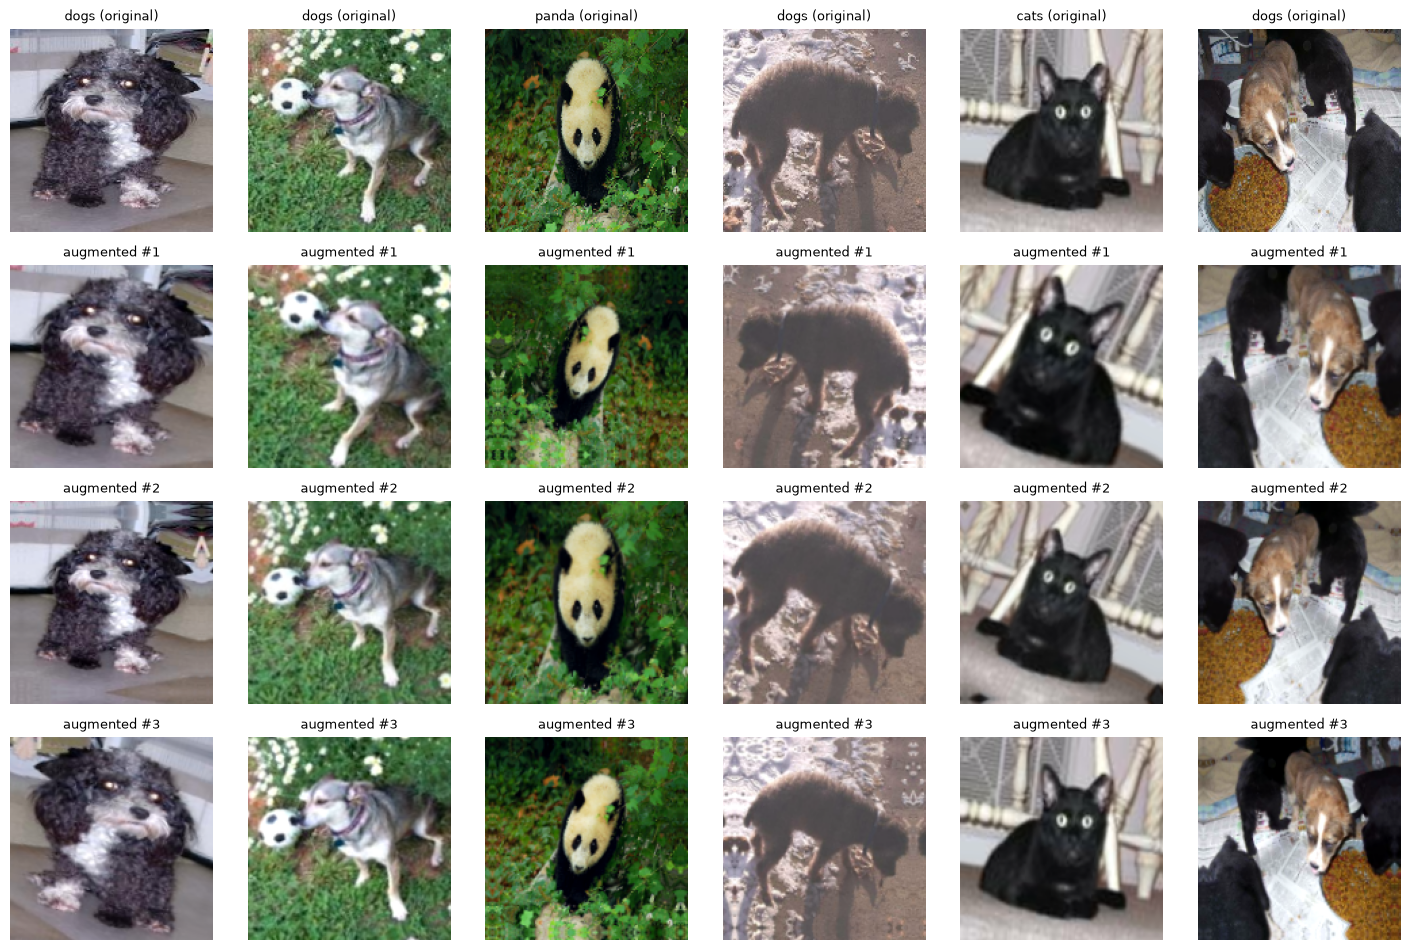

In [14]:
# Same images, three random augmentations each (top row = unaugmented)
sample_ids = [0, 1, 2, 3, 4, 5]
originals = tf.stack([load_image(train_p[i], train_y[i])[0] for i in sample_ids])
originals = tf.cast(originals, tf.float32)

fig, axes = plt.subplots(4, len(sample_ids), figsize=(2.4 * len(sample_ids), 9.6))
for j in range(len(sample_ids)):
    axes[0, j].imshow(originals[j].numpy().astype("uint8"))
    axes[0, j].set_title(f"{CLASSES[train_y[sample_ids[j]]]} (original)", fontsize=9)
for r in range(1, 4):
    aug = augmentation(originals, training=True).numpy()
    for j in range(len(sample_ids)):
        axes[r, j].imshow(np.clip(aug[j], 0, 255).astype("uint8"))
        axes[r, j].set_title(f"augmented #{r}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.7 Step 2 summary
- **Split:** 2,100 train / 450 validation / 450 test images, stratified (700 / 150 / 150 per class), seed 42, with no overlap between splits.
- **Pipeline:** RGB decode -> 150 x 150 -> `uint8` cache -> batches of 32 `float32` images in the 0-255 range, with one-hot labels of shape `(32, 3)`.
- **Augmentation:** flip, rotation, zoom, and contrast on the training split only.
- **Handed to Step 3:** `train_ds`, `val_ds`, `test_ds`, `CLASSES`, `IMG_SIZE`, `BATCH_SIZE`. Each model must include its own input scaling because the datasets deliver raw 0-255 pixels.

## Step 3: Baseline Model
A small CNN trained from scratch gives the number to beat. If the transfer model in Step 4 cannot clearly outperform it,
the pretrained backbone is not earning its cost.

### 3.1 Training helpers and the experiment log
Every experiment in Steps 3-5 goes through the same helpers so results are comparable:
- `fit_model` trains with a `ModelCheckpoint` (best weights saved to `../models/`) and `EarlyStopping` on validation loss, and restores the best epoch.
- `log_experiment` adds one row to the experiment log (train/val accuracy and val loss **at the best epoch**). Note that train accuracy is measured on augmented images, so it can sit slightly below validation accuracy.
- `plot_history` draws the loss/accuracy curves used to diagnose under/overfitting.
- `sanity_check` verifies the output shape and that the softmax outputs sum to 1.

In [4]:
import time
from datetime import date
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

experiment_log = []   # one dict per experiment
histories = {}        # experiment name -> keras History
trained = {}          # experiment name -> model (best-val-loss weights restored)


def fit_model(model, name, ds, epochs, patience=3, extra_callbacks=()):
    """Fit with checkpointing and early stopping on val_loss; the best epoch's weights are restored."""
    callbacks = [
        keras.callbacks.ModelCheckpoint(MODEL_DIR / f"{name}.weights.h5", monitor="val_loss",
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        *extra_callbacks,
    ]
    start = time.time()
    history = model.fit(ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    history.minutes = (time.time() - start) / 60
    histories[name], trained[name] = history, model
    return history


def log_experiment(num, name, change):
    h = histories[name].history
    best = int(np.argmin(h["val_loss"]))
    experiment_log.append({
        "#": num, "name": name, "date": date.today().isoformat(), "change": change,
        "train_acc": h["accuracy"][best], "val_acc": h["val_accuracy"][best], "val_loss": h["val_loss"][best],
        "best_epoch": best + 1, "epochs_run": len(h["loss"]), "minutes": histories[name].minutes,
    })
    return experiment_log[-1]


def show_log():
    log = pd.DataFrame(experiment_log).drop(columns="name")
    print(log.round({"train_acc": 4, "val_acc": 4, "val_loss": 4, "minutes": 1}).to_string(index=False))


def plot_history(name, title=None):
    h = histories[name].history
    best = int(np.argmin(h["val_loss"]))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(range(1, len(h[key]) + 1), h[key], label="train")
        ax.plot(range(1, len(h[key]) + 1), h["val_" + key], label="validation")
        ax.axvline(best + 1, color="gray", ls="--", lw=1, label=f"best epoch ({best + 1})")
        ax.set_title(f"{title or name}: {label}")
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()


def sanity_check(model):
    xb, _ = next(iter(val_ds))
    probs = model.predict(xb, verbose=0)
    assert probs.shape == (xb.shape[0], NUM_CLASSES), probs.shape
    assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-4), "softmax outputs must sum to 1"
    print(f"input {tuple(xb.shape)} -> output {probs.shape}, rows sum to 1")

### 3.2 Build the baseline CNN
Three convolution blocks (32 -> 64 -> 128 filters, each followed by max-pooling), global average pooling, a 128-unit dense layer
with dropout, and a 3-way softmax. The first layer rescales raw 0-255 pixels to 0-1, because Step 2 deliberately leaves scaling to the model.

In [16]:
def build_baseline():
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input((*IMG_SIZE, 3))
    x = layers.Rescaling(1 / 255)(inputs)
    for filters in (32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")


baseline = build_baseline()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
baseline.summary()
sanity_check(baseline)

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

input (32, 150, 150, 3) -> output (32, 3), rows sum to 1


### 3.3 Train the baseline
Adam (learning rate 1e-3), up to 25 epochs, stopping early once validation loss has not improved for 5 epochs.

Epoch 1/25


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 14s - 206ms/step - accuracy: 0.5052 - loss: 0.9631 - val_accuracy: 0.5600 - val_loss: 0.8860


Epoch 2/25


66/66 - 13s - 190ms/step - accuracy: 0.5400 - loss: 0.8562 - val_accuracy: 0.5689 - val_loss: 0.8473


...

66/66 - 12s - 188ms/step - accuracy: 0.6076 - loss: 0.7807 - val_accuracy: 0.5911 - val_loss: 0.7898


Epoch 8/25


66/66 - 12s - 188ms/step - accuracy: 0.6133 - loss: 0.7622 - val_accuracy: 0.6089 - val_loss: 0.8052


Epoch 9/25


66/66 - 12s - 187ms/step - accuracy: 0.6033 - loss: 0.7499 - val_accuracy: 0.5556 - val_loss: 0.8866


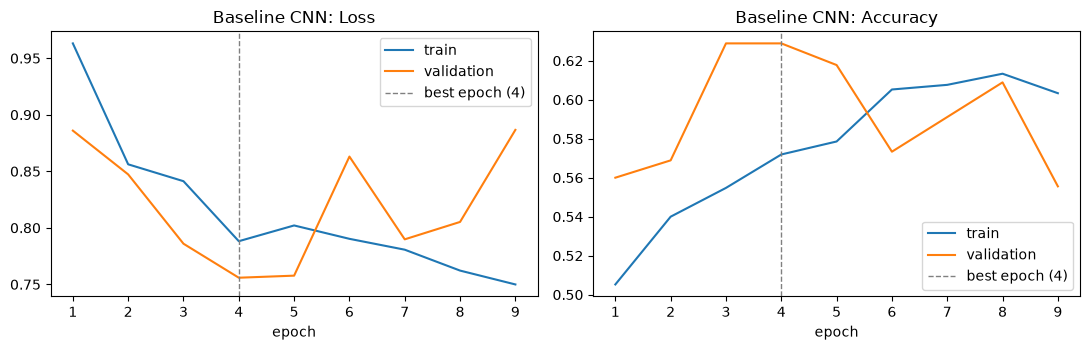

 #       date                            change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16 Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9


In [17]:
fit_model(baseline, "exp0_baseline_cnn", train_ds, epochs=25, patience=5)
plot_history("exp0_baseline_cnn", "Baseline CNN")
log_experiment(0, "exp0_baseline_cnn", "Baseline small CNN (from scratch)")
show_log()

### 3.4 Baseline insights
- **Result:** best validation accuracy **62.9%** (val loss 0.756) at epoch 4; training stopped at epoch 9. This is the number to beat.
- **Diagnosis: underfitting.** Training accuracy (57% at the best epoch, 60% at the end) is low and still climbing, and validation loss is noisy rather than diverging from training loss. The model has not learned the task well in 9 epochs; it is not overfitting.
- **Caveat:** early stopping (patience 5 on a noisy validation loss) ended training early. A longer schedule, a lower learning rate, or more capacity would probably lift this baseline, so the gap to the transfer model in Step 4 is partly a measure of how weak this small, briefly trained network is. It still serves its purpose: from-scratch learning on 2,100 images is much harder than reusing ImageNet features.

## Step 4: Transfer Learning Model (VGG19)
Reuse the convolutional features VGG19 learned on ImageNet and train only a small new classification head.

### 4.1 Build the model
- **Backbone:** `VGG19(include_top=False, weights="imagenet")` at 150 x 150 x 3, frozen. It is called with `training=False` so inference-mode behavior is used even after later unfreezing.
- **Preprocessing:** `vgg19.preprocess_input` (RGB -> BGR and ImageNet mean subtraction) is the first layer of the model, as planned in Step 2.
- **Head:** `GlobalAveragePooling2D` -> `Dense(256, relu)` -> `Dropout(0.3)` -> `Dense(3, softmax)`.
- The builder also supports MobileNetV2, which is used for the backbone comparison in Step 5.

In [18]:
BACKBONES = {
    "vgg19": (keras.applications.VGG19, keras.applications.vgg19.preprocess_input),
    "mobilenet_v2": (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
}


def build_transfer(backbone="vgg19", units=256, dropout=0.3):
    keras.utils.set_random_seed(SEED)
    app, preprocess = BACKBONES[backbone]
    base = app(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input((*IMG_SIZE, 3))
    x = layers.Lambda(preprocess, name=f"{backbone}_preprocess")(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"{backbone}_transfer"), base


def make_optimizer(name, lr):
    return {"adam": keras.optimizers.Adam(lr),
            "rmsprop": keras.optimizers.RMSprop(lr),
            "sgd": keras.optimizers.SGD(lr, momentum=0.9)}[name]


vgg, vgg_base = build_transfer("vgg19")
vgg.compile(optimizer=make_optimizer("adam", 1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
vgg.summary()
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in vgg.trainable_weights):,}")
sanity_check(vgg)

Model: "vgg19_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19_preprocess (Lambda)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,156,483 (76.89 MB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

trainable parameters: 132,099


input (32, 150, 150, 3) -> output (32, 3), rows sum to 1


### 4.2 Train the head (backbone frozen)
Adam at 1e-3 is a normal rate for a freshly initialised head. Up to 8 epochs with early stopping (patience 3).
The best head weights are saved and reused as the starting point for every fine-tuning experiment in Step 5.

Epoch 1/8


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 73s - 1s/step - accuracy: 0.8710 - loss: 0.9795 - val_accuracy: 0.9644 - val_loss: 0.2751


Epoch 2/8


66/66 - 72s - 1s/step - accuracy: 0.9376 - loss: 0.3445 - val_accuracy: 0.9578 - val_loss: 0.2143


...

66/66 - 72s - 1s/step - accuracy: 0.9724 - loss: 0.0966 - val_accuracy: 0.9622 - val_loss: 0.1748


Epoch 7/8


66/66 - 72s - 1s/step - accuracy: 0.9743 - loss: 0.0817 - val_accuracy: 0.9667 - val_loss: 0.1416


Epoch 8/8


66/66 - 71s - 1s/step - accuracy: 0.9752 - loss: 0.0788 - val_accuracy: 0.9667 - val_loss: 0.1715


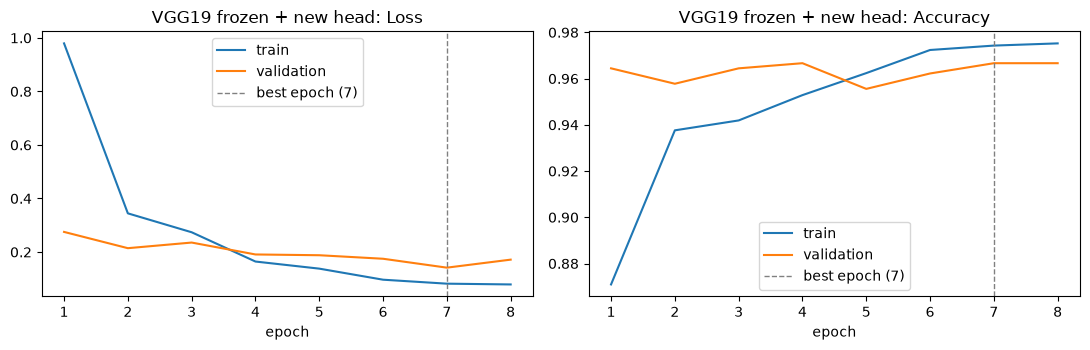

 #       date                              change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16   Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17 VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6


In [19]:
EPOCHS_TRANSFER = 8

fit_model(vgg, "exp1_vgg19_frozen", train_ds, epochs=EPOCHS_TRANSFER)
plot_history("exp1_vgg19_frozen", "VGG19 frozen + new head")
log_experiment(1, "exp1_vgg19_frozen", "VGG19 frozen + new head (Adam 1e-3)")
show_log()

### 4.3 Compare with the baseline

In [20]:
base_row, vgg_row = experiment_log[0], experiment_log[1]
print(f"baseline CNN : val acc {base_row['val_acc']:.4f}  val loss {base_row['val_loss']:.4f}")
print(f"VGG19 frozen : val acc {vgg_row['val_acc']:.4f}  val loss {vgg_row['val_loss']:.4f}")
print(f"improvement  : {100 * (vgg_row['val_acc'] - base_row['val_acc']):+.2f} points of validation accuracy")

baseline CNN : val acc 0.6289  val loss 0.7559
VGG19 frozen : val acc 0.9667  val loss 0.1416
improvement  : +33.78 points of validation accuracy


### 4.4 Transfer-model insights
- **Result:** best validation accuracy **96.7%** (val loss 0.142) at epoch 7, +33.8 points over the baseline, with only 132,099 trainable parameters (the new head). The very first epoch already reached 96.4% validation accuracy.
- **Diagnosis:** train accuracy (97.4%) and validation accuracy (96.7%) are close, so the model is not badly overfitting, but validation accuracy plateaus around 96-97% from epoch 1 while training loss keeps falling. The frozen features are strong; the remaining errors need either adapted features (fine-tuning) or more varied training images (augmentation).

## Step 5: Improving Accuracy
Each experiment changes **one variable** relative to the best configuration so far (the "incumbent"). After every run the
incumbent is updated only if validation accuracy improved (ties are broken by lower validation loss). Test data is not touched.

Planned experiments:
1. **Fine-tune** the last VGG19 conv block (`block5_*`) at a low learning rate (1e-5), starting from the trained head.
2. **Stronger augmentation** (adds translation and brightness, larger rotation/zoom/contrast).
3. **Optimizer: RMSprop** instead of Adam.
4. **Optimizer: SGD with momentum** (learning rate 1e-3, since plain SGD is too slow at 1e-5).
5. **Learning-rate scheduler** (`ReduceLROnPlateau`) on top of the early stopping already used everywhere.
6. **Backbone comparison:** MobileNetV2 with the same head-only recipe as experiment 1.

### 5.1 Experiment runner
All fine-tuning runs load the head weights saved by experiment 1, so they differ only in the variable being tested.

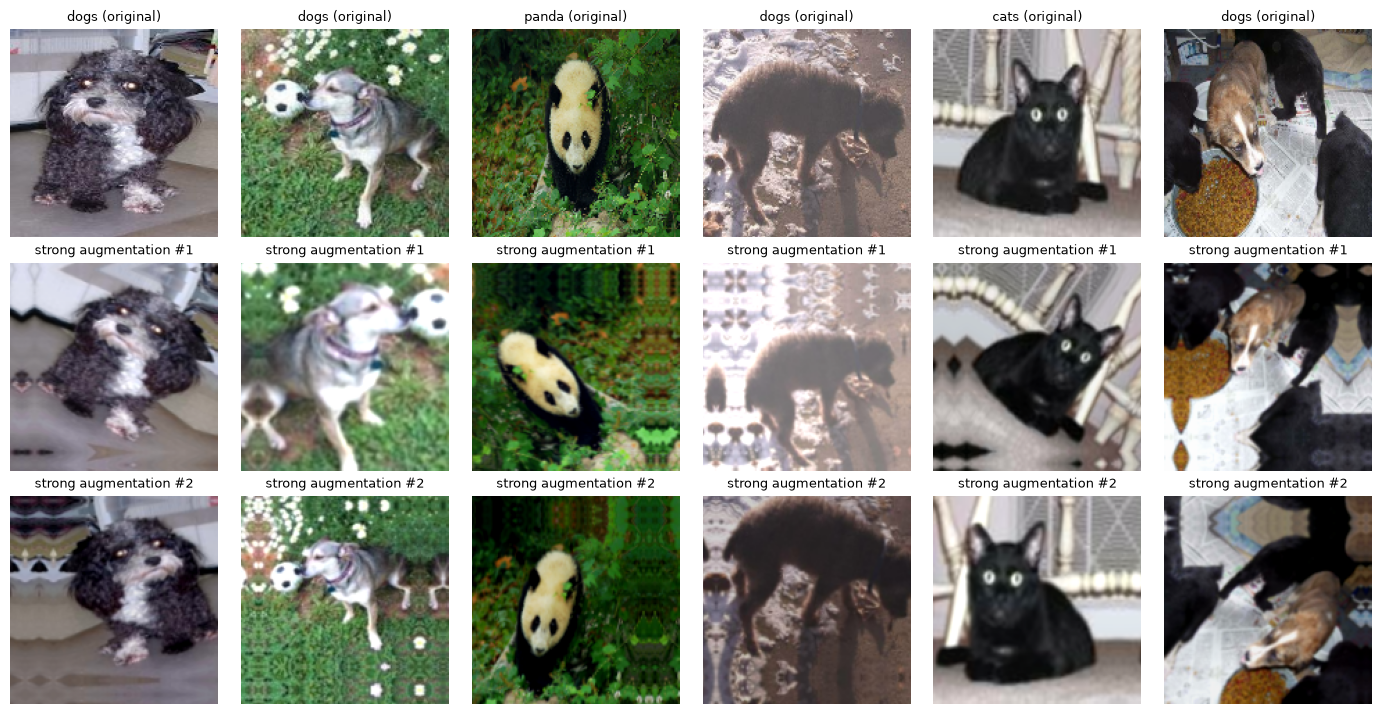

In [21]:
strong_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.3),
    layers.RandomTranslation(0.15, 0.15),
    layers.RandomContrast(0.3),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="strong_augmentation")


def make_train_ds(aug):
    """Same order as make_dataset(training=True) in Step 2, with a swappable augmentation model."""
    ds = tf.data.Dataset.from_tensor_slices((train_p, train_y)).map(load_image, num_parallel_calls=AUTOTUNE).cache()
    ds = ds.shuffle(len(train_p), seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (aug(tf.cast(x, tf.float32), training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_datasets = {"base": train_ds, "strong": make_train_ds(strong_augmentation)}

# Preview: same images, strong augmentation
originals = tf.cast(tf.stack([load_image(train_p[i], train_y[i])[0] for i in range(6)]), tf.float32)
fig, axes = plt.subplots(3, 6, figsize=(14, 7.2))
for j in range(6):
    axes[0, j].imshow(originals[j].numpy().astype("uint8"))
    axes[0, j].set_title(f"{CLASSES[train_y[j]]} (original)", fontsize=9)
for r in (1, 2):
    aug = strong_augmentation(originals, training=True).numpy()
    for j in range(6):
        axes[r, j].imshow(np.clip(aug[j], 0, 255).astype("uint8"))
        axes[r, j].set_title(f"strong augmentation #{r}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [22]:
HEAD_WEIGHTS = MODEL_DIR / "exp1_vgg19_frozen.weights.h5"

# Incumbent = best configuration so far; starts as experiment 1
best_cfg = dict(backbone="vgg19", finetune=False, optimizer="adam", lr=1e-3, aug="base", scheduler=False)
best_name = "exp1_vgg19_frozen"
best_key = (experiment_log[1]["val_acc"], -experiment_log[1]["val_loss"])


def run_experiment(num, label, adopt=True, **overrides):
    """Train best_cfg + overrides, plot, log; adopt it as the new incumbent if validation improves."""
    global best_cfg, best_name, best_key
    cfg = {**best_cfg, **overrides}
    name = f"exp{num}_{label}"
    model, base = build_transfer(cfg["backbone"])
    if cfg["finetune"]:
        model.load_weights(HEAD_WEIGHTS)                      # start from the trained head
        base.trainable = True
        for layer in base.layers:                             # unfreeze the last VGG19 conv block only
            layer.trainable = layer.name.startswith("block5")
    model.compile(optimizer=make_optimizer(cfg["optimizer"], cfg["lr"]),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    extra = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-7)] if cfg["scheduler"] else []
    fit_model(model, name, train_datasets[cfg["aug"]], epochs=EPOCHS_TRANSFER, extra_callbacks=extra)
    plot_history(name)
    row = log_experiment(num, name, ", ".join(f"{k}={v}" for k, v in overrides.items()))
    key = (row["val_acc"], -row["val_loss"])
    if adopt and key > best_key:
        best_cfg, best_name, best_key = cfg, name, key
        print(f"-> new incumbent: {name}")
    else:
        print(f"-> incumbent unchanged: {best_name}")
    show_log()


trainable_names = [l.name for l in vgg_base.layers if l.name.startswith("block5")]
print("layers unfrozen when fine-tuning:", trainable_names)

layers unfrozen when fine-tuning: ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_conv4', 'block5_pool']


### 5.2 Experiment 2: fine-tune the last conv block
Unfreezing `block5` lets the highest-level features adapt to cats, dogs, and pandas. The learning rate is lowered to 1e-5 so
the pretrained weights are nudged rather than destroyed.

Epoch 1/8


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 89s - 1s/step - accuracy: 0.9767 - loss: 0.0722 - val_accuracy: 0.9667 - val_loss: 0.1341


Epoch 2/8


66/66 - 87s - 1s/step - accuracy: 0.9867 - loss: 0.0403 - val_accuracy: 0.9667 - val_loss: 0.1420


Epoch 3/8


66/66 - 87s - 1s/step - accuracy: 0.9814 - loss: 0.0562 - val_accuracy: 0.9622 - val_loss: 0.1683


Epoch 4/8


66/66 - 87s - 1s/step - accuracy: 0.9881 - loss: 0.0377 - val_accuracy: 0.9644 - val_loss: 0.1661


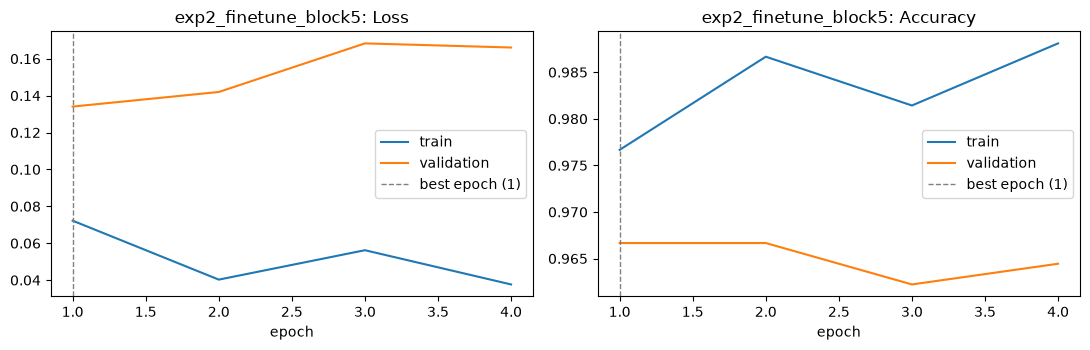

-> new incumbent: exp2_finetune_block5
 #       date                              change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16   Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17 VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6
 2 2026-10-17             finetune=True, lr=1e-05     0.9767   0.9667    0.1341           1           4      5.8


In [23]:
run_experiment(2, "finetune_block5", finetune=True, lr=1e-5)

**Experiment 2 result:** validation accuracy unchanged at **96.7%**, validation loss slightly lower (0.134 vs 0.142). The best epoch was the first one; after that validation loss rose (0.134 -> 0.142 -> 0.168) while training accuracy climbed to 98.8%, and early stopping ended the run at epoch 4. Fine-tuning `block5` overfits within one or two epochs on 2,100 images with the light augmentation from Step 2. It is adopted as the incumbent only through the validation-loss tie-break, so it is not a real accuracy gain on its own.

### 5.3 Experiment 3: stronger augmentation
Same model as the incumbent, trained on the more aggressive augmentation shown above. Validation data is still not augmented.

Epoch 1/8


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 90s - 1s/step - accuracy: 0.9190 - loss: 0.2710 - val_accuracy: 0.9711 - val_loss: 0.1076


Epoch 2/8


66/66 - 88s - 1s/step - accuracy: 0.9314 - loss: 0.1898 - val_accuracy: 0.9822 - val_loss: 0.0857


...

66/66 - 86s - 1s/step - accuracy: 0.9505 - loss: 0.1471 - val_accuracy: 0.9822 - val_loss: 0.0705


Epoch 7/8


66/66 - 90s - 1s/step - accuracy: 0.9471 - loss: 0.1313 - val_accuracy: 0.9800 - val_loss: 0.0933


Epoch 8/8


66/66 - 90s - 1s/step - accuracy: 0.9600 - loss: 0.1071 - val_accuracy: 0.9800 - val_loss: 0.0790


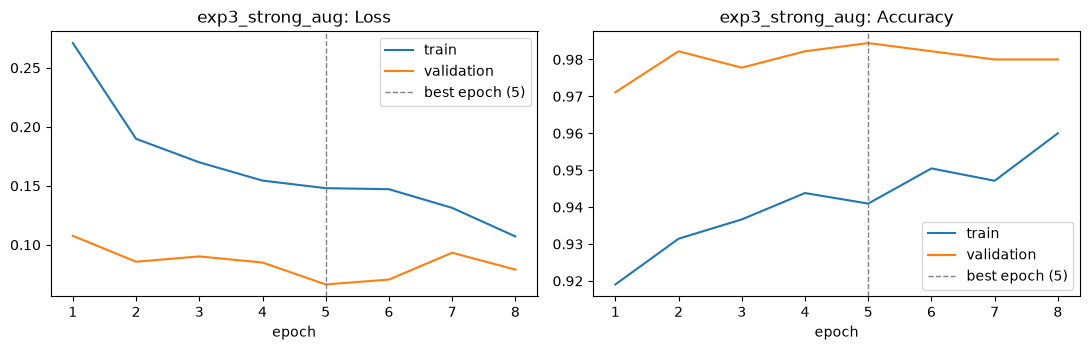

-> new incumbent: exp3_strong_aug
 #       date                              change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16   Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17 VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6
 2 2026-10-17             finetune=True, lr=1e-05     0.9767   0.9667    0.1341           1           4      5.8
 3 2026-10-17                          aug=strong     0.9410   0.9844    0.0664           5           8     11.8


In [24]:
run_experiment(3, "strong_aug", aug="strong")

**Experiment 3 result:** validation accuracy rose to **98.4%** (val loss 0.066), the biggest single gain: +1.8 points, about 8 more correct validation images. Training accuracy (94.1% on heavily augmented images) now sits *below* validation accuracy throughout (augmented images are harder than clean ones) and validation loss stays flat while training loss falls, so the quick overfitting seen in experiment 2 is gone. With a fine-tuned backbone, more varied training data was what mattered. Adopted as the new incumbent.

### 5.4 Experiment 4: RMSprop optimizer

Epoch 1/8


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 87s - 1s/step - accuracy: 0.9186 - loss: 0.2548 - val_accuracy: 0.9622 - val_loss: 0.1228


Epoch 2/8


66/66 - 86s - 1s/step - accuracy: 0.9371 - loss: 0.2053 - val_accuracy: 0.9689 - val_loss: 0.1102


...

66/66 - 86s - 1s/step - accuracy: 0.9524 - loss: 0.1429 - val_accuracy: 0.9800 - val_loss: 0.0758


Epoch 7/8


66/66 - 87s - 1s/step - accuracy: 0.9538 - loss: 0.1209 - val_accuracy: 0.9800 - val_loss: 0.0855


Epoch 8/8


66/66 - 88s - 1s/step - accuracy: 0.9619 - loss: 0.1102 - val_accuracy: 0.9800 - val_loss: 0.0912


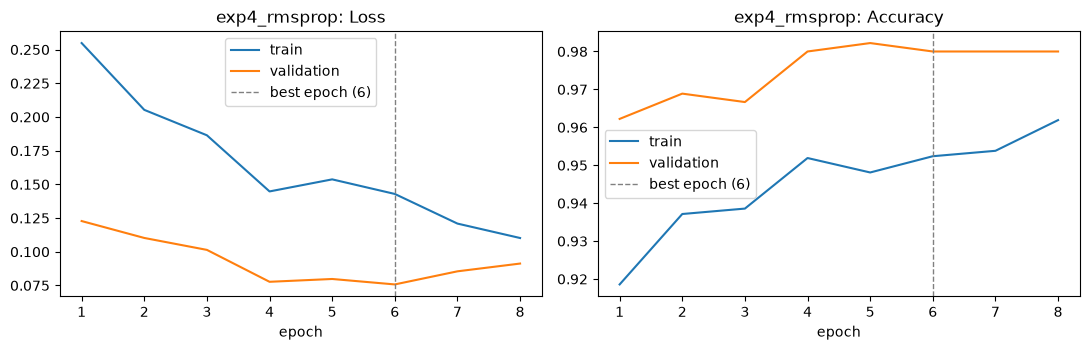

-> incumbent unchanged: exp3_strong_aug
 #       date                              change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16   Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17 VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6
 2 2026-10-17             finetune=True, lr=1e-05     0.9767   0.9667    0.1341           1           4      5.8
 3 2026-10-17                          aug=strong     0.9410   0.9844    0.0664           5           8     11.8
 4 2026-10-17                   optimizer=rmsprop     0.9524   0.9800    0.0758           6           8     11.6


In [25]:
run_experiment(4, "rmsprop", optimizer="rmsprop")

**Experiment 4 result:** RMSprop reached **98.0%** (val loss 0.076), slightly below Adam's 98.4%. That is a difference of about 2 validation images and is within noise, but it does not beat the incumbent, so Adam stays.

### 5.5 Experiment 5: SGD with momentum
Learning rate 1e-3 with momentum 0.9 (the learning rate has to change together with the optimizer, otherwise SGD barely moves).

Epoch 1/8


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 87s - 1s/step - accuracy: 0.8419 - loss: 0.4420 - val_accuracy: 0.9200 - val_loss: 0.3970


Epoch 2/8


66/66 - 86s - 1s/step - accuracy: 0.9048 - loss: 0.2464 - val_accuracy: 0.9533 - val_loss: 0.1164


...

66/66 - 87s - 1s/step - accuracy: 0.9510 - loss: 0.1242 - val_accuracy: 0.9689 - val_loss: 0.1036


Epoch 7/8


66/66 - 87s - 1s/step - accuracy: 0.9519 - loss: 0.1274 - val_accuracy: 0.9689 - val_loss: 0.1030


Epoch 8/8


66/66 - 88s - 1s/step - accuracy: 0.9610 - loss: 0.1069 - val_accuracy: 0.9711 - val_loss: 0.1124


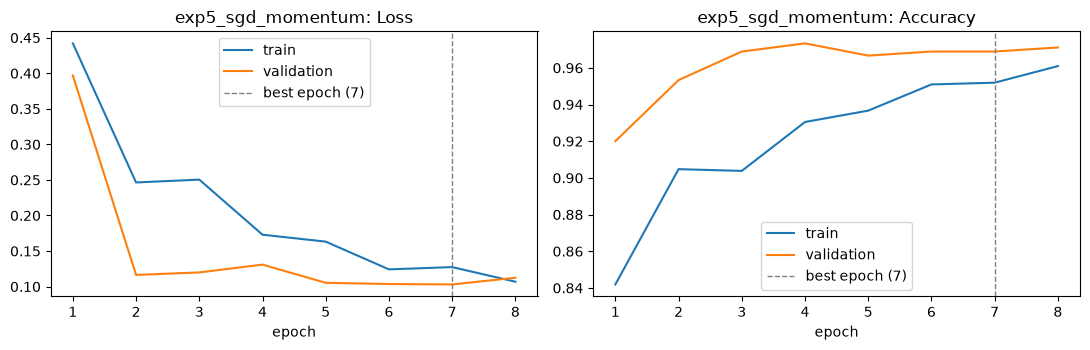

-> incumbent unchanged: exp3_strong_aug
 #       date                              change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16   Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17 VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6
 2 2026-10-17             finetune=True, lr=1e-05     0.9767   0.9667    0.1341           1           4      5.8
 3 2026-10-17                          aug=strong     0.9410   0.9844    0.0664           5           8     11.8
 4 2026-10-17                   optimizer=rmsprop     0.9524   0.9800    0.0758           6           8     11.6
 5 2026-10-17             optimizer=sgd, lr=0.001     0.9519   0.9689    0.1030           7           8     11.6


In [26]:
run_experiment(5, "sgd_momentum", optimizer="sgd", lr=1e-3)

**Experiment 5 result:** SGD with momentum reached **96.9%** (val loss 0.103). It started slowest (92.0% after epoch 1) and was still improving slowly at epoch 8, so more epochs might help it, but within this budget it is clearly behind Adam and RMSprop. Adam stays.

### 5.6 Experiment 6: learning-rate scheduler
`ReduceLROnPlateau` multiplies the learning rate by 0.3 whenever validation loss fails to improve for one epoch.

Epoch 1/8


C:\Users\apowe\Developer\AI-ML\zoo-cnn-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 90s - 1s/step - accuracy: 0.9233 - loss: 0.2674 - val_accuracy: 0.9667 - val_loss: 0.1164 - learning_rate: 1.0000e-05


Epoch 2/8


66/66 - 88s - 1s/step - accuracy: 0.9319 - loss: 0.1972 - val_accuracy: 0.9711 - val_loss: 0.1017 - learning_rate: 1.0000e-05


...

66/66 - 88s - 1s/step - accuracy: 0.9424 - loss: 0.1544 - val_accuracy: 0.9756 - val_loss: 0.1047 - learning_rate: 1.0000e-05


Epoch 5/8


66/66 - 87s - 1s/step - accuracy: 0.9590 - loss: 0.1204 - val_accuracy: 0.9756 - val_loss: 0.0983 - learning_rate: 3.0000e-06


Epoch 6/8


66/66 - 87s - 1s/step - accuracy: 0.9481 - loss: 0.1242 - val_accuracy: 0.9778 - val_loss: 0.0967 - learning_rate: 9.0000e-07


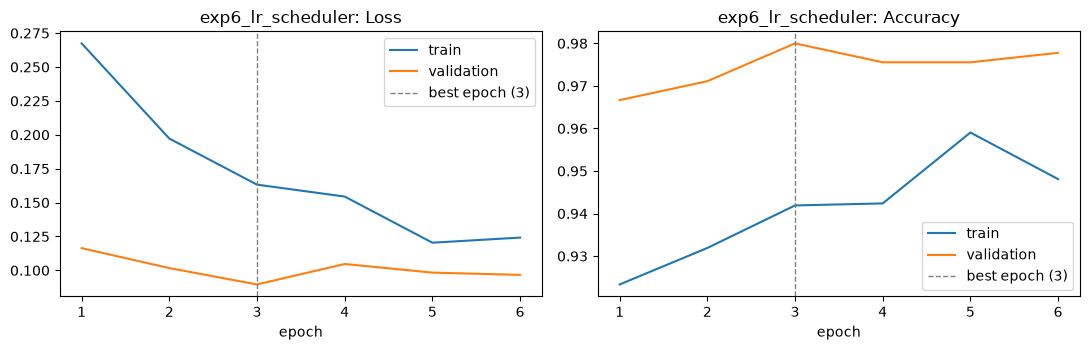

-> incumbent unchanged: exp3_strong_aug
 #       date                              change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16   Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17 VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6
 2 2026-10-17             finetune=True, lr=1e-05     0.9767   0.9667    0.1341           1           4      5.8
 3 2026-10-17                          aug=strong     0.9410   0.9844    0.0664           5           8     11.8
 4 2026-10-17                   optimizer=rmsprop     0.9524   0.9800    0.0758           6           8     11.6
 5 2026-10-17             optimizer=sgd, lr=0.001     0.9519   0.9689    0.1030           7           8     11.6
 6 2026-10-17                      scheduler=True     0.9419   0.9800    0.0896           3           6      8.8


In [27]:
run_experiment(6, "lr_scheduler", scheduler=True)

**Experiment 6 result:** with `ReduceLROnPlateau`, validation accuracy was **98.0%** (val loss 0.090, best epoch 3). The scheduler cut the learning rate twice (1e-5 -> 3e-6 -> 9e-7) and early stopping ended the run at epoch 6. Validation loss was noisy rather than steadily plateauing, and the rate was already low (1e-5) to begin with, so further cuts had little room to help. No improvement over the incumbent.

### 5.7 Experiment 7: MobileNetV2 backbone
A much smaller network (about 2.3M parameters versus 20M for VGG19). It gets exactly the experiment-1 recipe (frozen backbone,
same head, Adam 1e-3, base augmentation) so it is compared directly with experiment 1. It does not change the incumbent.

C:\Users\apowe\AppData\Local\Temp\ipykernel_16872\1940398245.py:10: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = app(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))



      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step


 221184/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


1376256/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2736128/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

...

66/66 - 12s - 178ms/step - accuracy: 0.9500 - loss: 0.1506 - val_accuracy: 0.9667 - val_loss: 0.1139


Epoch 3/8


66/66 - 12s - 177ms/step - accuracy: 0.9581 - loss: 0.1166 - val_accuracy: 0.9822 - val_loss: 0.0605


Epoch 4/8


66/66 - 12s - 178ms/step - accuracy: 0.9695 - loss: 0.0960 - val_accuracy: 0.9733 - val_loss: 0.0678


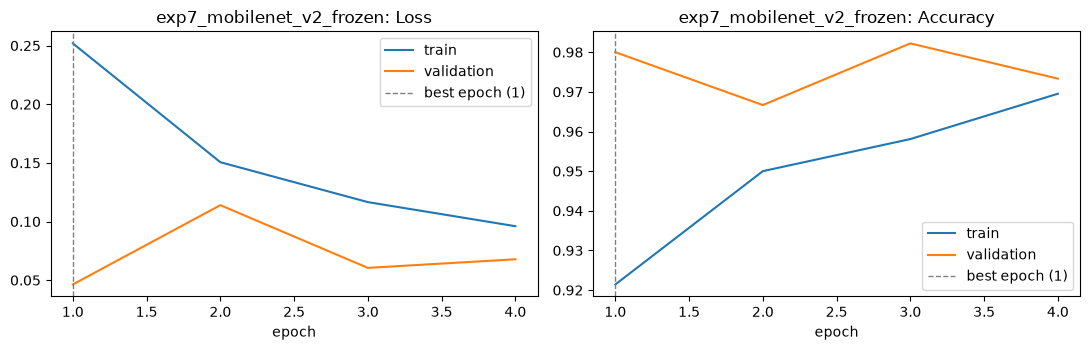

-> incumbent unchanged: exp3_strong_aug
 #       date                                                                                     change  train_acc  val_acc  val_loss  best_epoch  epochs_run  minutes
 0 2026-10-16                                                          Baseline small CNN (from scratch)     0.5719   0.6289    0.7559           4           9      1.9
 1 2026-10-17                                                        VGG19 frozen + new head (Adam 1e-3)     0.9743   0.9667    0.1416           7           8      9.6
 2 2026-10-17                                                                    finetune=True, lr=1e-05     0.9767   0.9667    0.1341           1           4      5.8
 3 2026-10-17                                                                                 aug=strong     0.9410   0.9844    0.0664           5           8     11.8
 4 2026-10-17                                                                          optimizer=rmsprop     0.9524   0.

In [28]:
run_experiment(7, "mobilenet_v2_frozen", adopt=False, backbone="mobilenet_v2", finetune=False,
               optimizer="adam", lr=1e-3, aug="base", scheduler=False)

**Experiment 7 result:** MobileNetV2 with the experiment-1 recipe reached **98.0%** validation accuracy with the lowest validation loss of any run (**0.046**, best epoch 1), but in under one minute of training versus about 10 minutes for the frozen VGG19 head, which got 96.7%. Its validation accuracy bounced between 96.7% and 98.2% over four epochs, so the single best epoch is a noisy estimate. It is clearly the more efficient backbone. It did not beat the incumbent on validation accuracy (98.0% vs 98.4%, 2 images), and VGG19 is the backbone the assignment suggests. Note that Keras warned that 150 x 150 is not one of MobileNetV2's native sizes and loaded the default 224 x 224 weights; they still work for any input of at least 32 x 32.

KeyError: 'val_acc'

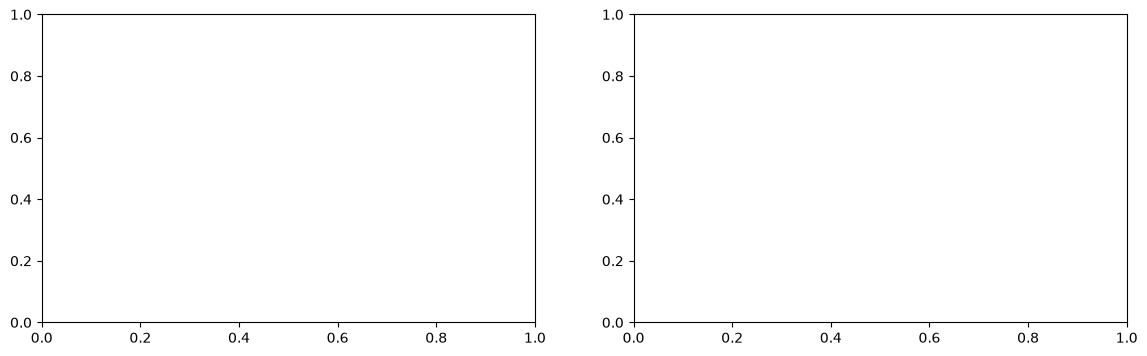

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

log = pd.DataFrame(experiment_log)
labels = [f"{r['#']}" for r in experiment_log]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(labels, log["val_acc"], color="#4C72B0")
axes[0].set_ylim(max(0, log["val_acc"].min() - 0.05), 1.0)
for i, v in enumerate(log["val_acc"]):
    axes[0].text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
axes[0].set_xlabel("experiment #")
axes[0].set_ylabel("validation accuracy (best epoch)")
axes[0].set_title("Validation accuracy per experiment")

for r in experiment_log:
    axes[1].plot(range(1, r["epochs_run"] + 1), histories[r["name"]].history["val_accuracy"], marker="o", ms=3, label=f"#{r['#']} {r['name'].split('_', 1)[1]}")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
axes[1].set_title("Validation accuracy curves")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

show_log()
print("\nIncumbent (best by validation):", best_name, best_cfg)

### 5.9 Step 5 summary
| # | Change | Val acc | Val loss | Outcome |
|---|---|---|---|---|
| 0 | Baseline CNN | 62.9% | 0.756 | number to beat |
| 1 | VGG19 frozen + head | 96.7% | 0.142 | +33.8 points over baseline |
| 2 | Fine-tune `block5`, lr 1e-5 | 96.7% | 0.134 | same accuracy, overfits after epoch 1 (adopted on tie-break) |
| 3 | Strong augmentation | **98.4%** | **0.066** | **+1.8 points, best model** |
| 4 | RMSprop | 98.0% | 0.076 | no gain |
| 5 | SGD + momentum | 96.9% | 0.103 | worse |
| 6 | LR scheduler | 98.0% | 0.090 | no gain |
| 7 | MobileNetV2 (frozen) | 98.0% | 0.046 | comparable accuracy, about 10x faster |

- **What helped:** a pretrained backbone (+33.8 points), then stronger augmentation on top of fine-tuning (+1.8 points). Everything else was neutral or worse.
- **Stop rule:** after experiment 3, experiments 4, 5, and 6 each failed to improve validation accuracy by 0.5% (three consecutive), so the search was stopped at the planned seven transfer experiments plus the baseline.
- **Resolution limit:** the validation set has 450 images, so one image is 0.22 points. The 98.0-98.4% results differ by 0-2 images, and experiment 3 is only *marginally* ahead of experiments 4, 6, and 7. The only clear conclusions are the large ones (pretraining, then augmentation); the choice of experiment 3 as the final model is a reasonable but not statistically decisive pick.

## Step 6: Final Evaluation
The model is chosen using **validation** metrics only (highest validation accuracy, ties broken by lower validation loss).
The test set is then evaluated **once**.

### 6.1 Select the model and evaluate on the test set

In [30]:
final_row = max(experiment_log, key=lambda r: (r["val_acc"], -r["val_loss"]))
final_name = final_row["name"]
final_model = trained[final_name]
print("Selected model:", final_name, "| validation accuracy", round(final_row["val_acc"], 4))

probs = final_model.predict(test_ds, verbose=0)
assert probs.shape == (len(test_p), NUM_CLASSES) and np.allclose(probs.sum(axis=1), 1.0, atol=1e-4)
y_true = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_ds])   # test_ds is unshuffled, so order is fixed
y_pred = probs.argmax(axis=1)
assert (y_true == test_y).all(), "test labels must line up with the file order"

test_acc = (y_true == y_pred).mean()
test_loss = keras.losses.categorical_crossentropy(tf.one_hot(y_true, NUM_CLASSES), probs).numpy().mean()
print(f"\nTest accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}")
print(f"Validation accuracy was {final_row['val_acc']:.4f}  ->  gap {100 * (final_row['val_acc'] - test_acc):+.2f} points")

Selected model: exp3_strong_aug | validation accuracy 0.9844



Test accuracy: 0.9800   Test loss: 0.0703
Validation accuracy was 0.9844  ->  gap +0.44 points


### 6.2 Confusion matrix and classification report

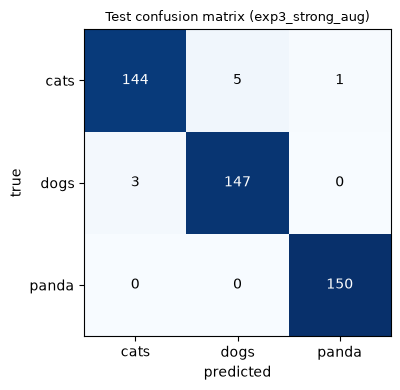

              precision    recall  f1-score   support

        cats      0.980     0.960     0.970       150
        dogs      0.967     0.980     0.974       150
       panda      0.993     1.000     0.997       150

    accuracy                          0.980       450
   macro avg      0.980     0.980     0.980       450
weighted avg      0.980     0.980     0.980       450



In [31]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), CLASSES)
ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Test confusion matrix ({final_name})", fontsize=9)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

### 6.3 Misclassified test images
The most confident mistakes first (up to 8), to see whether the errors are genuine model weaknesses or ambiguous / mislabeled images.

9 of 450 test images misclassified; showing 8

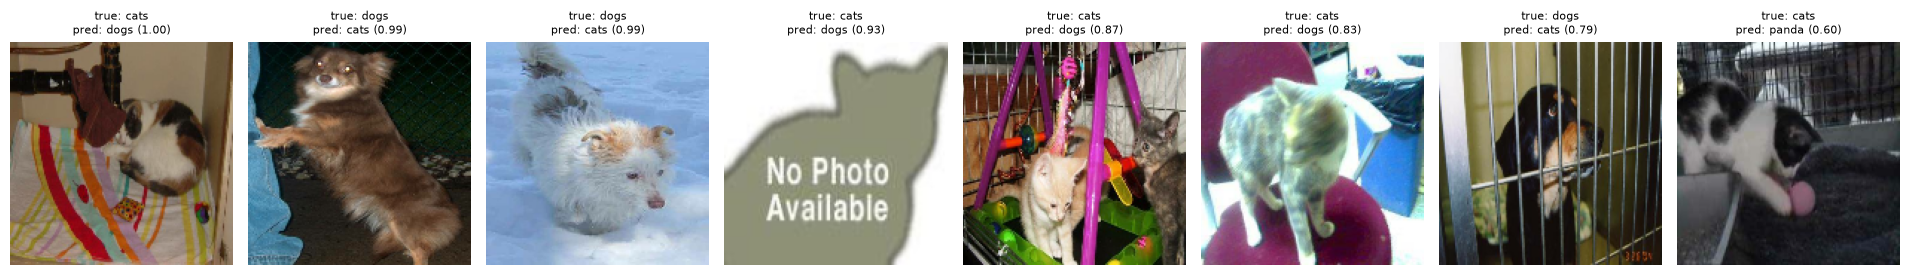

In [32]:
x_test = np.concatenate([x.numpy() for x, _ in test_ds]).astype("uint8")
wrong = np.where(y_true != y_pred)[0]
wrong = wrong[np.argsort(-probs[wrong].max(axis=1))][:8]
print(f"{(y_true != y_pred).sum()} of {len(y_true)} test images misclassified; showing {len(wrong)}")

if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.4 * len(wrong), 3.2), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        ax.imshow(x_test[i])
        ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({probs[i].max():.2f})", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 6.4 Final evaluation insights
- **Test result:** the selected model (experiment 3: fine-tuned VGG19 with strong augmentation) scores **98.0% accuracy** on the test set (441 of 450, test loss 0.070), against 98.4% on validation. The 0.4-point (2 image) gap is what we would expect from a 450-image sample, so there is no sign that selecting on validation overfit it.
- **Per class:** pandas are perfect (150 of 150, recall 1.00). Cats have recall 0.960 (144 of 150) and dogs 0.980 (147 of 150); precision is 0.980 for cats and 0.967 for dogs. Of the 9 errors, 8 are cat/dog confusions (5 cats predicted as dogs, 3 dogs predicted as cats) and 1 is a cat predicted as a panda. This matches the Step 1 prediction that cats and dogs would be confused most.
- **The errors:** the most confident mistakes are mostly hard or poor images: a dog photographed in a cage, two cats sharing one frame, a fluffy dog in snow, and a cat standing on a chair. One test "cat" is a grey **"No Photo Available" placeholder** that contains no cat at all, so that error is a data problem and not a model problem. The most confident error (a curled-up cat predicted as a dog at 1.00) shows the model can be fully certain and still wrong.

## Step 7: Write-up

### Exploration insights (Step 1)
The dataset has 3,000 JPEG images, exactly 1,000 each of cats, dogs, and pandas, so accuracy is a fair metric. Nothing was corrupt; 7 panda images are grayscale and are expanded to 3 channels. Image sizes vary widely (about 55-1600 px wide, median about 499 x 375), so every image is resized to **150 x 150 x 3**.

### Pipeline (Step 2)
Stratified 70 / 15 / 15 split by file path (2,100 / 450 / 450) with seed 42 and a leakage check, RGB decode, resize, `uint8` cache, one-hot labels, and augmentation on the training split only. Scaling is done inside each model, so one pipeline serves every experiment.

### Models and hyperparameters
- **Option chosen:** Option 2, transfer learning, with a from-scratch CNN as the baseline.
- **Baseline (Step 3):** 3 conv blocks (32/64/128) + global average pooling + Dense(128) + Dropout(0.3) + softmax; Adam 1e-3.
- **Final model (Steps 4-5):** VGG19 (ImageNet weights) with `vgg19.preprocess_input`; `block1`-`block4` frozen, `block5` fine-tuned; head = global average pooling -> Dense(256, relu) -> Dropout(0.3) -> Dense(3, softmax). Loss `categorical_crossentropy`, Adam at 1e-5, batch size 32, strong augmentation (flip, rotation 0.15, zoom 0.3, translation 0.15, contrast 0.3, brightness 0.2), early stopping on validation loss (patience 3, best weights restored; best epoch 5).

### What improved accuracy, and why
| Stage | Val accuracy |
|---|---|
| Baseline CNN from scratch | 62.9% |
| VGG19 frozen backbone + new head | 96.7% |
| + fine-tuning `block5` | 96.7% (overfits after one epoch) |
| + strong augmentation | **98.4%** |

1. **Pretrained features** account for nearly all of the gain (+33.8 points). ImageNet already contains many cat and dog breeds and a giant-panda class, so VGG19's features separate these classes without learning from scratch on 2,100 images.
2. **Strong augmentation with fine-tuning** added a further +1.8 points. Fine-tuning alone overfits quickly with so little data; the extra variety in framing, scale, and brightness removed that overfitting (train accuracy stayed below validation accuracy and validation loss stayed low and flat).
3. **Optimizer choice, learning-rate scheduling, and the lighter MobileNetV2 backbone** gave no improvement in validation accuracy beyond the noise level (about 2 images). RMSprop (98.0%) and the scheduler (98.0%) matched Adam closely; SGD with momentum (96.9%) was slower to converge.

### Final results
**Test accuracy 98.0% (441 / 450), test loss 0.070**, measured once on data never used for training or model selection. Pandas are perfect; 8 of the 9 errors are cat/dog confusions.

### Limitations
- **Small validation and test sets** (450 images each): one image is 0.22 points, so differences below about 0.5% between the top experiments are not meaningful. Results come from a single seed; repeated runs or cross-validation would give error bars.
- **Weak baseline:** the from-scratch CNN stopped early at 62.9% while still underfitting, so the +33.8-point gap overstates how much better transfer learning is than a well-tuned small CNN.
- **One-change-at-a-time search** was greedy and limited to about 8 runs, so combinations (for example RMSprop with a scheduler, or a larger unfrozen portion of VGG19) were not explored.
- **Data quality:** at least one image is a "No Photo Available" placeholder labeled as a cat, and images with several animals or tiny, low-resolution subjects remain hard. Squashing 4:3 photos to square was not compared against cropping.
- **Training was CPU-only** (about 62 minutes for the full notebook), which limited epochs and the experiment budget.

### Requirements coverage
- [x] Option chosen (Option 2) and stated in the notebook
- [x] Data exploration: image count, sample images, image size choice (Step 1)
- [x] Baseline model fit on train / validation data (Step 3)
- [x] Loss / accuracy plots evaluated (Steps 3-5)
- [x] Architecture and / or hyperparameter variations tried (Step 5: fine-tuning, augmentation, three optimizers, scheduler, backbone)
- [x] Accuracy improved over baseline, with explanation (62.9% -> 98.4% validation, 98.0% test)
- [x] Softmax output + `categorical_crossentropy` loss